In [1]:
import numpy as np
import pandas as pd
from IPython.display import display

import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['grid.linestyle'] = "--"
plt.rcParams['grid.alpha'] = 0.5
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.left'] = False
plt.rcParams['axes.spines.bottom'] = False
plt.rcParams['axes.labelsize'] = 10

# Movimiento Browniano con deriva

Dado un movimiento bowniano $B_t$, el movimiento browniano con deriva $X_t$ se define explícitamente en el tiempo continuo mediante la ecuación:

$$X_t = \mu t + \sigma B_t$$

Donde:

* $\mu \in \mathbb{R}$ es el **coeficiente de deriva** (drift). Representa la velocidad constante o la tendencia macroscópica del proceso.
* $\sigma > 0$ es el **coeficiente de difusión**. Escala la amplitud del ruido aleatorio.

**Ejemplo**: Encuentre la probabilidad de que el movimiento browniano con parámetro deriva, mu=0.6, y varianza, sigma^2=0.25, tome valores entre 1 y 3 al tiempo 4.

$$ X_t = 0.6 t + 0.5 B_t$$

**Solucion analitica**: Buscamos

$$P(1 < X_4 < 3)$$

Si sustiumos el lado derecho se obtiene

$$P(1 < 0.6(4) + 0.5 B_4 < 3) = P(-2.8 < B_4 < 1.2)$$

Como $B_t \sim \mathcal{N}(0,t)$ entonces

$$P(-2.8 < B_4 < 1.2) = 0.645$$

**Solucion numerica/simulación**:

In [2]:
def mb_deriva(mu, sigma, T, n, time_output = True):
    # Definimos el movimiento browniano
    dt = np.sqrt(T/n)
    w = np.zeros(n + 1)
    t = np.linspace(0,T,n+1)
    w[0] = 0
    for i in range(1, n+1):
        z = np.random.normal(0,1)
        w[i] = w[i-1] + dt*z
    
    # Generamos el movimiento con deriva
    x = mu * t + sigma * w
    if time_output: return x, t
    else: return x

'La probabilidad de que el proceso termine entre 1 y 3 es: 0.6534'

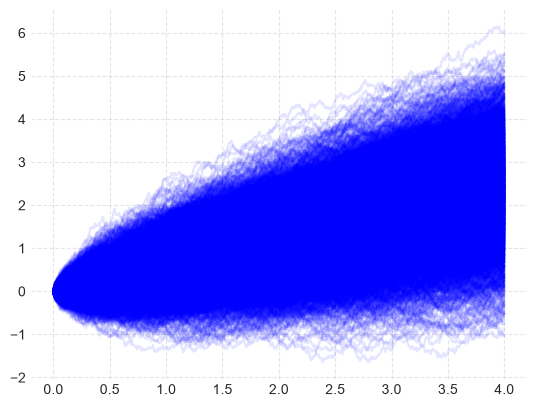

None

In [3]:
drift = 0.6
sigma = 0.5
m = 5000
n = 1000
T = 4
caminos = np.zeros((m, n+1))
caminos[0], t = mb_deriva(drift, sigma, T, n, time_output=True)
for i in range(m):
    caminos[i] = mb_deriva(drift, sigma, T, n, time_output = False)

prob = np.sum((caminos[:,-1] > 1) & (caminos[:,-1] < 3)) / m
display(f"La probabilidad de que el proceso termine entre 1 y 3 es: {prob:.4f}")
p = plt.plot(t, caminos.T, color='blue', alpha=0.1)
display(plt.show(p))